**IMPORTANT: for this notebook choose the inverse_folding kernel and not the special_course one (impossible to fit the required versions within the global environment other wise)** 


In [1]:
import os
import sys
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import numpy as np
from scipy import stats
from pathlib import Path


# This section is not relevant anymore as we now use our own in-house utils
# # Getting the path of the NetTCR-struc repository
# repo_root = Path("../repositories/NetTCR-struc").resolve()

# if str(repo_root) not in sys.path:
#   sys.path.insert(0, str(repo_root))

# # We can now directly import from nettcrstruc
# from nettcrstruc.dataset.esm_if1_utils import (
#     compute_esm_if1_on_pdb,
#     forward_pass,
#     initialize_esm_if1_model,
# )

sys.path.insert(0, str(Path.cwd().resolve().parent))
from utils.esm_if1_mutscan import (
    compute_esm_if1_on_pdb,
    forward_pass,
    initialize_esm_if1_model
)

#import missing packages of esm_if1 utils as a precaution

import biotite.structure as struc
import torch

### Analysis dependant global variables

In [2]:
pep_folder = "NLFR_analysis"
wt_seq = "NLFRRVWEL"
pep_short = "NLFR"
pep_file = "TCRneo_duplex_fingerprint_data_WT_TCR.tsv"
HLA_allele = "HLA-B*08:01"

# pep_folder = "EVDP_analysis"
# wt_seq = "EVDPIGHLY"
# pep_short = "EVDP"
# pep_file = "TCRA3_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*01:01"

# pep_folder = "SLLQ_analysis"
# wt_seq = "SLLQHLIGL"
# pep_short = "SLLQ"
# pep_file = "PRAMEb_duplex_fingerprint_data_WT_TCR.tsv"
# HLA_allele = "HLA-A*02:01"

fig_folder = f"/net/well/pool/projects2/s253730/projects/pred_TCR_fingerprints/figures/{pep_folder}/"

### Functions (visualization for heatmap, and correlation)

In [ ]:
def plot_heatmap(matrix, labels, title, scale_center, fig_name = "", save_fig = False):

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.heatmap(
        matrix,
        cmap="RdBu",
        center=scale_center,
        cbar_kws={"label": labels},
        ax=ax,
    )


    # Highlighting the WT sequence 
    for pos, aa in enumerate(wt_seq, start=1):
        if aa in matrix.index :
            y = matrix.index.get_loc(aa)
            ax.add_patch(
                patches.Rectangle(
                    (pos, y), 1, 1, fill=False, edgecolor="black", lw=2
                )
            )

    # Crossing out the residues without data
    for r_idx, aa in enumerate(matrix.index):
        for c_idx, pos in enumerate(matrix.columns):
            if pd.isna(matrix.loc[aa, pos]):
                ax.text(
                    c_idx + 0.5,
                    r_idx + 0.5,
                    "X",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=11,
                )

    ax.set_title(f"{title} - {HLA_allele} + {wt_seq}")
    ax.set_xlabel("Peptide_pos")
    ax.set_ylabel("Peptide_res")
    plt.tight_layout()

    if save_fig == True:
        plt.savefig(
          os.path.join(fig_folder, fig_name), dpi=300
      )
        
    plt.show()

def compute_columnwise_pcc(df_ref, df_pred):
    df_ref = df_ref.copy()
    df_pred = df_pred.copy()
    df_ref.columns = [int(c) for c in df_ref.columns]
    df_pred.columns = [int(c) for c in df_pred.columns]

    records = []
    common_cols = [col for col in df_ref.columns if col in df_pred.columns]

    for pos in common_cols:
        combined = pd.concat([df_ref[pos].rename("ref"), df_pred[pos].rename("pred")], axis=1).dropna()
        
        x = combined["ref"].astype(float)
        y = combined["pred"].astype(float)

        # Pearson requires at least 3 points and non-zero standard deviation
        if len(x) >= 3 and x.std() > 1e-8 and y.std() > 1e-8:
            p_res = stats.pearsonr(x, y)
            s_res = stats.spearmanr(x, y)
            pcc, pcc_pval = p_res.statistic, p_res.pvalue
            scc, scc_pval = s_res.statistic, s_res.pvalue
        else:
            pcc, pcc_pval, scc, scc_pval = np.nan, np.nan, np.nan, np.nan

        records.append({
            "Peptide_pos": pos,
            "PCC": pcc,
            "p_value_pcc": pcc_pval,
            "SCC": scc,
            "p_value_scc": scc_pval,
            "n_points": len(x)
        })

    return pd.DataFrame(records)


def plot_bars(ax, df, metric_name, pval_col, title):
    bars = ax.bar(
        df["Peptide_pos"],
        df[metric_name],
        color="#4C72B0",
        edgecolor="black",
        width=0.6,
        alpha=0.85
    )

    # Add significance stars
    for idx, row in df.iterrows():
        val = row[metric_name]
        pval = row[pval_col]
        if not np.isnan(val):
            star = "***" if pval < 0.001 else ("**" if pval < 0.01 else ("*" if pval < 0.05 else ""))
            y_pos = val + (0.02 if val >= 0 else -0.06)
            ax.text(
                row["Peptide_pos"],
                y_pos,
                star,
                ha="center",
                va="bottom" if val >= 0 else "top",
                fontsize=11,
                fontweight="bold"
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylim(-1.05, 1.15)
    ax.set_xticks(range(1, 10))
    ax.set_xlabel("Peptide position")
    ax.set_title(title, fontsize=12)





## IF scoring on WT structure (mutational scan)

### Import IF model and input data (with the code from NetTCR-struc)

Previous work with the average ll computed from the original esm repo (through the IF_mut_scan.sh file in src) should be ignored

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
esm_if1_model, alphabet = initialize_esm_if1_model(device)


# If structure is not available in pdb, perform the docking analysis first in src 
# (contains a step converting .cif structure files in .pdb ones)

wt_link = f"../data/{pep_folder}/af3_output_base3/structures_pdb_cleaned/{pep_short}-P0_WT.pdb"
chain_ids = ['A', 'C', 'D', 'E']



/net/well/pool/projects2/s253730/utils/Miniconda/envs/inverse_folding/lib/python3.9/site-packages/esm/pretrained.py:215: UserWarning: Regression weights not found, predicting contacts will not produce correct results.
  warnings.warn(


Run this cell to perform the IF

In [21]:
esm_output = compute_esm_if1_on_pdb(wt_link, esm_if1_model, alphabet, chain_ids, "C")

### Exporting the IF results (and importing it if needed)

In [22]:
out_dir = Path(f"../data/{pep_folder}/af3_output_base3")
out_dir.mkdir(parents=True, exist_ok=True)
torch.save(esm_output, out_dir / "esm_if_output_raw.pt")

In [4]:
esm_output = torch.load(f"../data/{pep_folder}/af3_output_base3/esm_if_output_raw.pt")

### Conditional sequence log-likelihoods for given backbone coordinates

This has to be run after the IF_mut_scan.sh sbatch script in src/ (**this version is not to be used anymore**)

In [ ]:
# csv_if_path = f"../results/{pep_folder}/esm_if_scores.csv"
# df_esm = pd.read_csv(csv_if_path)

# wt_ll = df_esm.loc[df_esm["seqid"].str.contains("WT"), "log_likelihood"].values[0]
# df_esm["delta_ll"] = df_esm["log_likelihood"] - wt_ll

# records = []
# for _, row in df_esm.iterrows():
#   sid = row["seqid"]
#   ll = row["log_likelihood"]
#   dll = row["delta_ll"]

#   if "WT" in sid:
#     for pos, aa in enumerate(wt_seq, start=1):
#       records.append({
#           "Peptide_pos": pos,
#           "Peptide_res": aa,
#           "log_likelihood": ll,
#           "delta_ll": 0.0,
#       })

#   else:
#     # Format 'P{pos}_{res}'
#     parts = sid.split("_")
#     pos = int(parts[0].replace("P", ""))
#     res = parts[1]
#     records.append({
#         "Peptide_pos": pos,
#         "Peptide_res": res,
#         "log_likelihood": ll,
#         "delta_ll": dll,
#     })

# df_parsed = pd.DataFrame(records)
# mat_delta_ll = df_parsed.pivot(index="Peptide_res", columns="Peptide_pos", values="delta_ll").sort_index()

Actual version to use for the ouput of the in-house IF anlaysis

In [7]:
probs_tensor = esm_output["C"]["probability"]  
wt_seq = esm_output["C"]["sequence"]  
seq_len = len(wt_seq)
standard_aa = list("ACDEFGHIKLMNPQRSTVWY")
aa_indices = {aa: alphabet.get_idx(aa) for aa in standard_aa}

rows = []

wt_lls_per_pos = []
for pos_idx, wt_aa in enumerate(wt_seq):
  p_wt = probs_tensor[pos_idx, aa_indices[wt_aa]].item()
  wt_lls_per_pos.append(np.log(p_wt))

rows.append({
    "seqid": f"{pep_short}-P0_WT",
    "position": 0,
    "wt_aa": "-",
    "mut_aa": "-",
    "probability": np.nan,
    "log_likelihood": 0.0, 
    "delta_ll": 0.0,
})

for pos_idx, wt_aa in enumerate(wt_seq):
  pos_num = pos_idx + 1  
  wt_ll_at_pos = wt_lls_per_pos[pos_idx]

  for mut_aa in standard_aa:
    p_mut = probs_tensor[pos_idx, aa_indices[mut_aa]].item()
    ll_mut = np.log(p_mut)
    delta = ll_mut - wt_ll_at_pos

    seq_id = (
        f"{pep_short}-P{pos_num}_WT"
        if mut_aa == wt_aa
        else f"{pep_short}-P{pos_num}_{mut_aa}"
    )

    rows.append({
        "seqid": seq_id,
        "Peptide_pos": pos_num,
        "wt_aa": wt_aa,
        "Peptide_res": mut_aa,
        "probability": p_mut,
        "log_likelihood": ll_mut, 
        "delta_ll": delta, 
    })


df_esm = pd.DataFrame(rows)
df_plot = df_esm[~df_esm["seqid"].str.contains("P0_WT")].copy()
mat_delta_ll = df_plot.pivot(index="Peptide_res", columns="Peptide_pos", values="delta_ll").sort_index()
mat_IF_prob = df_plot.pivot(index="Peptide_res", columns="Peptide_pos", values="probability").sort_index()

### Export IF heatmap (for scoring and logo plots)

In [24]:
mat_delta_ll.to_csv(f"../results/{pep_folder}/heatmaps/matrix_ESM_IF.tsv", sep="\t")

In [ ]:
# this is repetitive with the previous code, but it is inherited from the first version of the analysis

# csv_if_path = f"../results/{pep_folder}/esm_if_scores.csv"
# df_esm = pd.read_csv(csv_if_path)

# wt_ll = df_esm.loc[df_esm["seqid"].str.contains("WT"), "log_likelihood"].values[0]
# df_esm["delta_ll"] = df_esm["log_likelihood"] - wt_ll

# records = []
# for _, row in df_esm.iterrows():
#   sid = row["seqid"]
#   ll = row["log_likelihood"]
#   dll = row["delta_ll"]

#   if "WT" in sid:
#     for pos, aa in enumerate(wt_seq, start=1):
#       records.append({
#           "Peptide_pos": pos,
#           "Peptide_res": aa,
#           "log_likelihood": ll,
#           "delta_ll": 0.0,
#       })

#   else:
#     # Format 'P{pos}_{res}'
#     parts = sid.split("_")
#     pos = int(parts[0].replace("P", ""))
#     res = parts[1]
#     records.append({
#         "Peptide_pos": pos,
#         "Peptide_res": res,
#         "log_likelihood": ll,
#         "delta_ll": dll,
#     })

# df_parsed = pd.DataFrame(records)
# mat_delta_ll = df_parsed.pivot(index="Peptide_res", columns="Peptide_pos", values="delta_ll").sort_index()

### Visualization

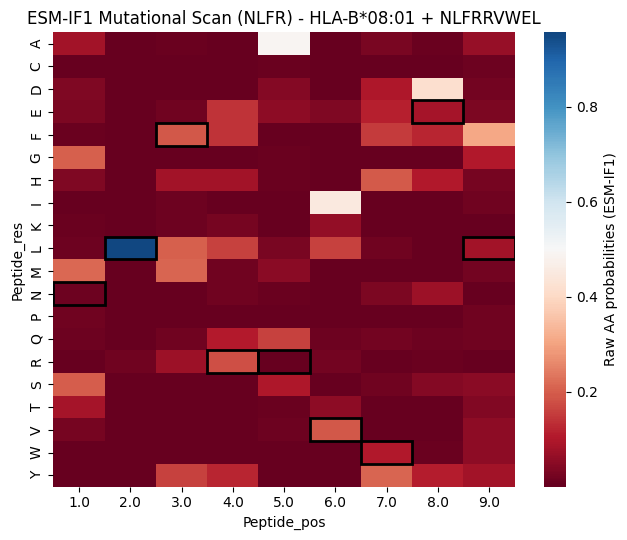

In [10]:
plot_heatmap(
    matrix=mat_IF_prob,
    labels=r"Raw AA probabilities (ESM-IF1)",
    title=f"ESM-IF1 Mutational Scan ({pep_short})",
    scale_center=0.5,
    fig_name = "heatmap_ESM_prob",
    save_fig=True,
)

### Correlation with previous AF metric and exp data

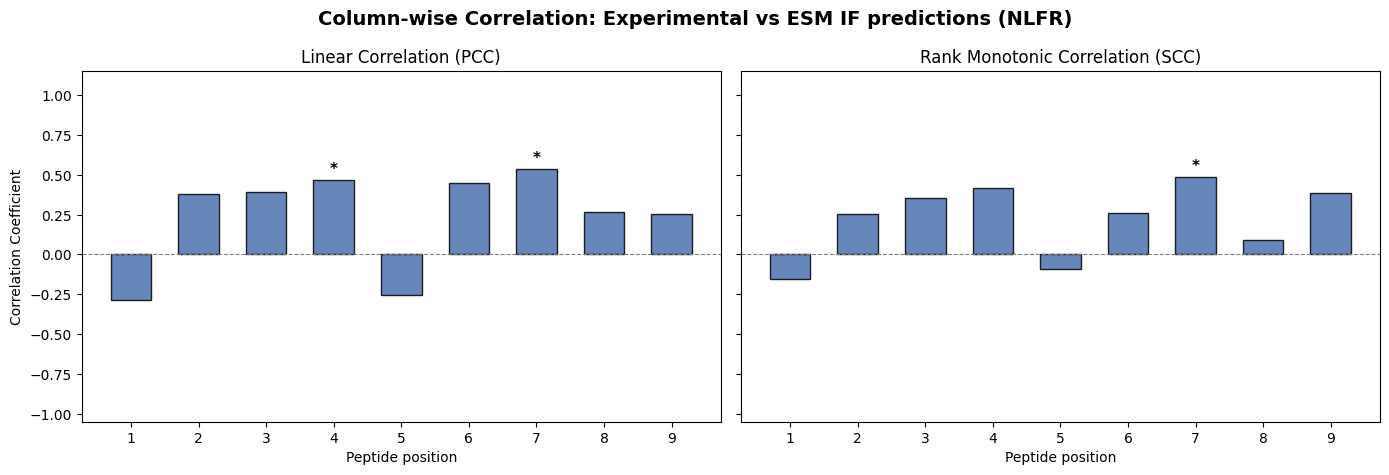

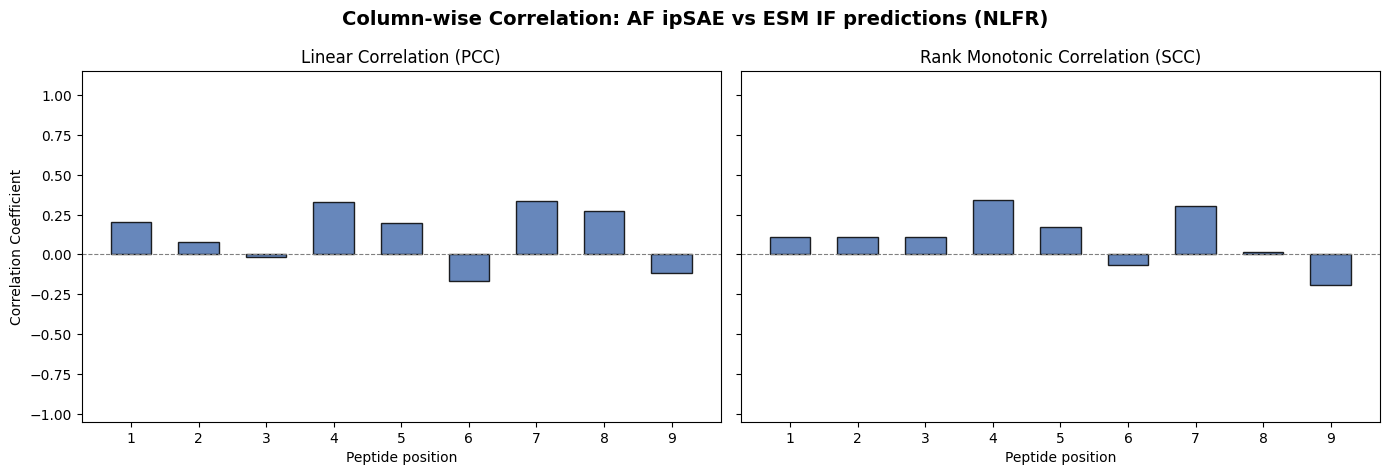

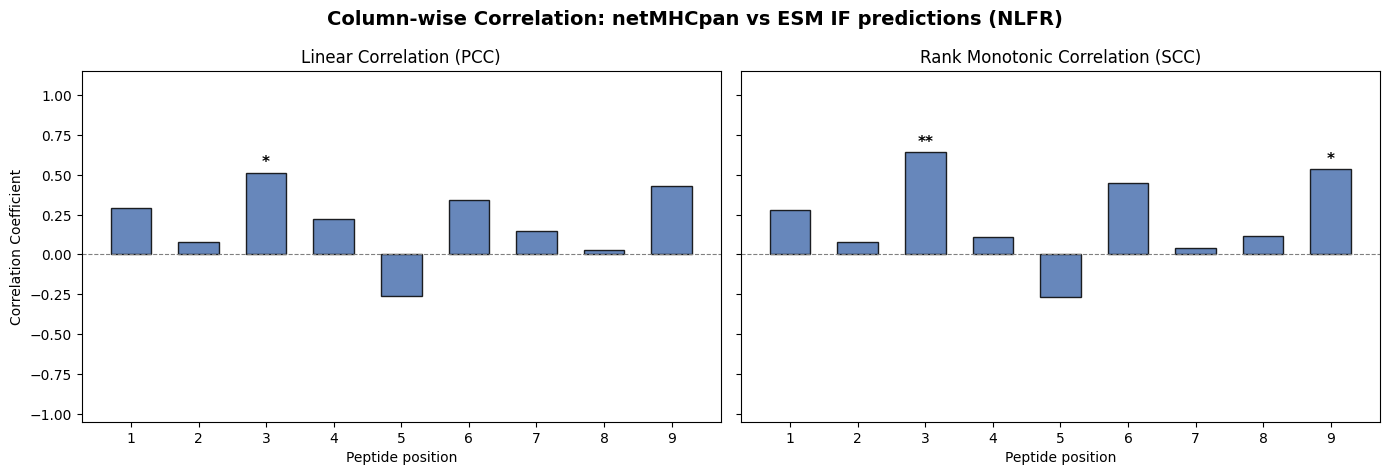

In [26]:
matrix_exp = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_exp_duplex.tsv", sep="\t", index_col=0)
matrix_af = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_af_interface.tsv", sep="\t", index_col=0)
matrix_pmhc = pd.read_csv(f"../results/{pep_folder}/heatmaps/matrix_score_netmhcpan.tsv", sep="\t", index_col=0)

pcc_if_exp = compute_columnwise_pcc(matrix_exp, mat_delta_ll)
pcc_if_ipsae = compute_columnwise_pcc(matrix_af, mat_delta_ll)
pcc_if_pmhc = compute_columnwise_pcc(matrix_pmhc, mat_delta_ll)


fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_if_exp,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_if_exp.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_if_exp,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_if_exp.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig1.suptitle(f"Column-wise Correlation: Experimental vs ESM IF predictions ({pep_short})", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_exp_esm"), dpi=300)
plt.show()




fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_if_ipsae,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_if_ipsae.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_if_ipsae,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_if_ipsae.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig2.suptitle(f"Column-wise Correlation: AF ipSAE vs ESM IF predictions ({pep_short})", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_ipsae_esm"), dpi=300)
plt.show()




fig3, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
plot_bars(
    ax1,
    pcc_if_pmhc,
    metric_name="PCC",
    pval_col="p_value_pcc" if "p_value_pcc" in pcc_if_pmhc.columns else "p_value",
    title="Linear Correlation (PCC)"
)
ax1.set_ylabel("Correlation Coefficient")


plot_bars(
    ax2,
    pcc_if_pmhc,
    metric_name="SCC",
    pval_col="p_value_scc" if "p_value_scc" in pcc_if_pmhc.columns else "p_value",
    title="Rank Monotonic Correlation (SCC)"
)

fig3.suptitle(f"Column-wise Correlation: netMHCpan vs ESM IF predictions ({pep_short})", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(fig_folder, "pcc_pmhc_esm"), dpi=300)
plt.show()